In [27]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_style("whitegrid")

# Load dataset
df = pd.read_csv(
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/historical_automobile_sales.csv"
)

# Convert Date to datetime if needed
df["Date"] = pd.to_datetime(df["Date"])

print(df.head())
print(df.shape)
print(df.columns.tolist())


        Date  Year Month  Recession  Consumer_Confidence  Seasonality_Weight  \
0 1980-01-31  1980   Jan          1               108.24                0.50   
1 1980-02-29  1980   Feb          1                98.75                0.75   
2 1980-03-31  1980   Mar          1               107.48                0.20   
3 1980-04-30  1980   Apr          1               115.01                1.00   
4 1980-05-31  1980   May          1                98.72                0.20   

       Price  Advertising_Expenditure  Competition     GDP  Growth_Rate  \
0  27483.571                     1558            7  60.223     0.010000   
1  24308.678                     3048            4  45.986    -0.309594   
2  28238.443                     3137            3  35.141    -0.308614   
3  32615.149                     1653            7  45.673     0.230596   
4  23829.233                     1319            4  52.997     0.138197   

   unemployment_rate  Automobile_Sales     Vehicle_Type        City 

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

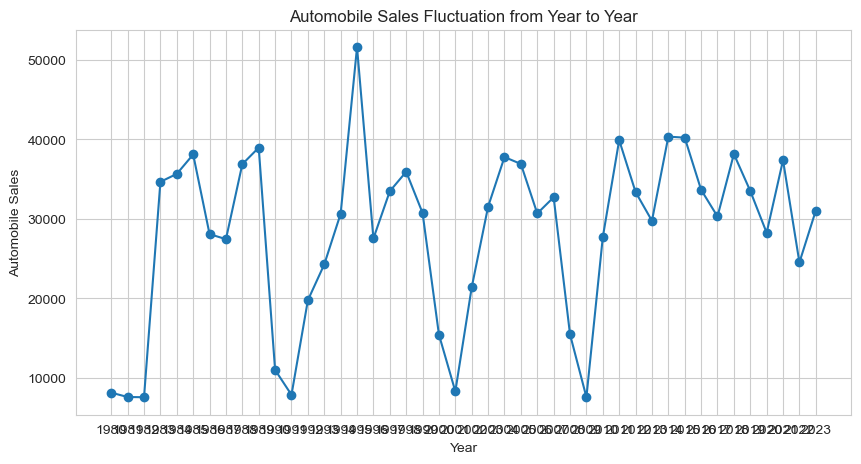

In [28]:
# Task 1.1
yearly_sales = df.groupby("Year")["Automobile_Sales"].sum()

plt.figure(figsize=(10, 5))
plt.plot(yearly_sales.index, yearly_sales.values, marker="o")
plt.title("Automobile Sales Fluctuation from Year to Year")
plt.xlabel("Year")
plt.ylabel("Automobile Sales")
plt.xticks(yearly_sales.index)
plt.grid(True)
plt.show()


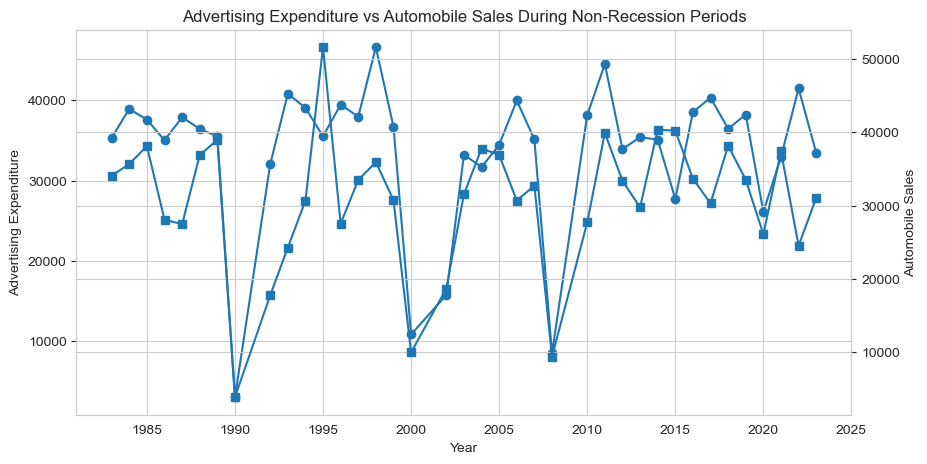

Correlation:
                         Advertising_Expenditure  Automobile_Sales
Advertising_Expenditure                 1.000000         -0.035389
Automobile_Sales                       -0.035389          1.000000


In [29]:
# Task 1.2
non_recession = df[df["Recession"] == 0]

advertising_sales = non_recession.groupby("Year")[["Advertising_Expenditure", "Automobile_Sales"]].sum()

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(
    advertising_sales.index,
    advertising_sales["Advertising_Expenditure"],
    marker="o",
    label="Advertising Expenditure"
)
ax1.set_xlabel("Year")
ax1.set_ylabel("Advertising Expenditure")

ax2 = ax1.twinx()
ax2.plot(
    advertising_sales.index,
    advertising_sales["Automobile_Sales"],
    marker="s",
    label="Automobile Sales"
)
ax2.set_ylabel("Automobile Sales")

plt.title("Advertising Expenditure vs Automobile Sales During Non-Recession Periods")
plt.show()

print("Correlation:")
print(non_recession[["Advertising_Expenditure", "Automobile_Sales"]].corr())


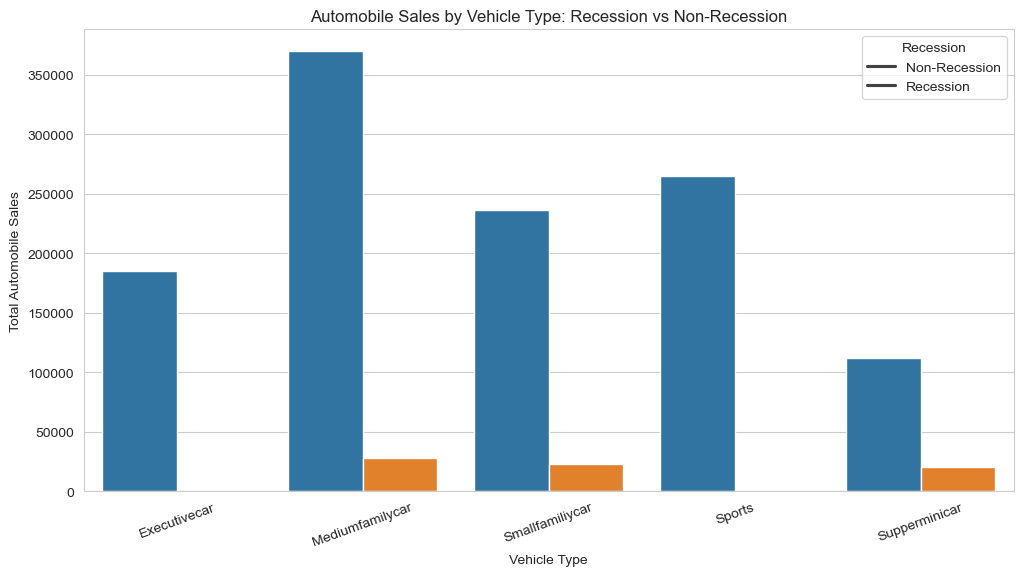

In [30]:
# Task 1.3
vehicle_sales = df.groupby(["Vehicle_Type", "Recession"])["Automobile_Sales"].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(
    data=vehicle_sales,
    x="Vehicle_Type",
    y="Automobile_Sales",
    hue="Recession"
)
plt.title("Automobile Sales by Vehicle Type: Recession vs Non-Recession")
plt.xlabel("Vehicle Type")
plt.ylabel("Total Automobile Sales")
plt.xticks(rotation=20)
plt.legend(title="Recession", labels=["Non-Recession", "Recession"])
plt.show()


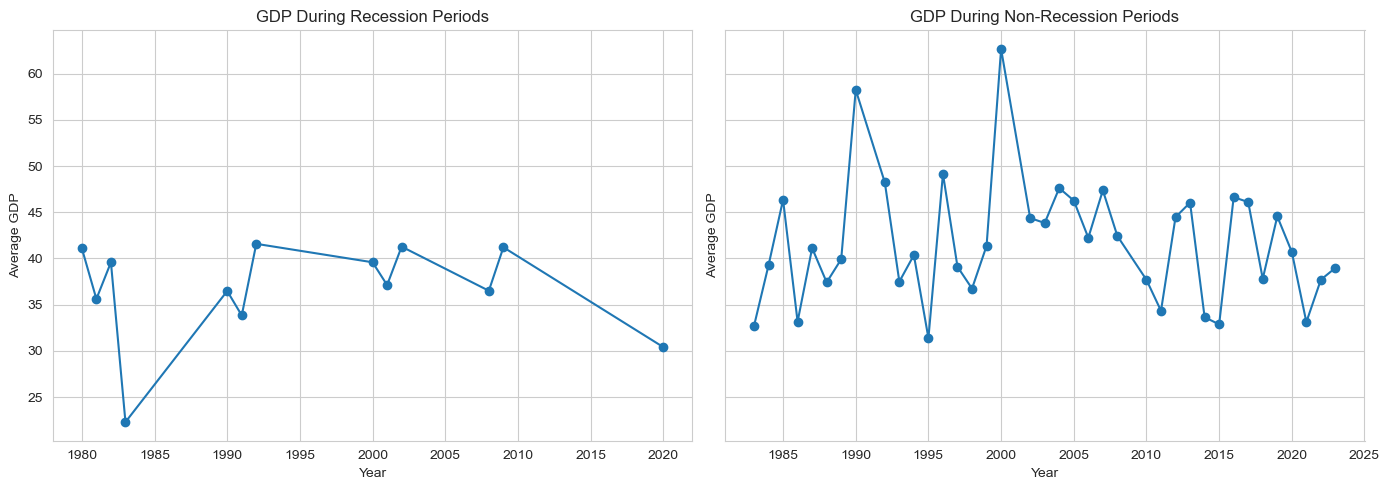

In [31]:
# Task 1.4
recession_gdp = df[df["Recession"] == 1].groupby("Year")["GDP"].mean()
non_recession_gdp = df[df["Recession"] == 0].groupby("Year")["GDP"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

axes[0].plot(recession_gdp.index, recession_gdp.values, marker="o")
axes[0].set_title("GDP During Recession Periods")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Average GDP")
axes[0].grid(True)

axes[1].plot(non_recession_gdp.index, non_recession_gdp.values, marker="o")
axes[1].set_title("GDP During Non-Recession Periods")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Average GDP")
axes[1].grid(True)

plt.tight_layout()
plt.show()


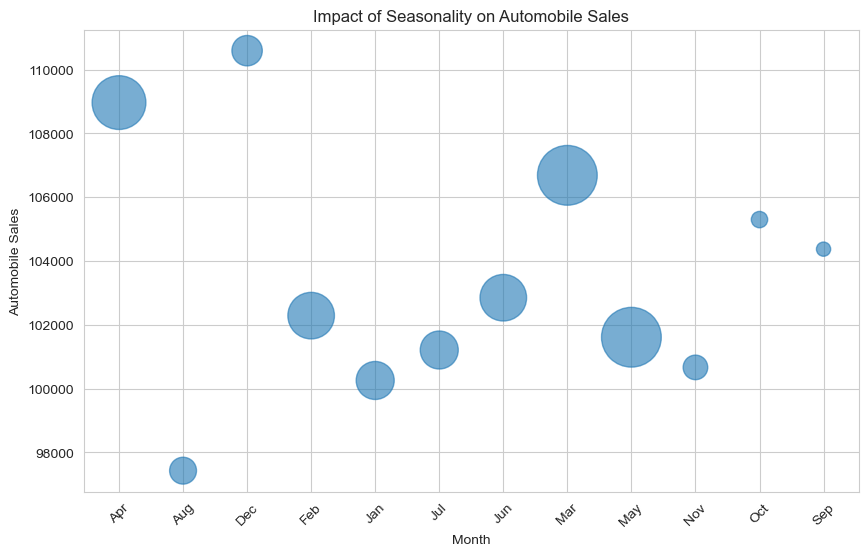

In [32]:
# Task 1.5
seasonality = df.groupby("Month").agg({
    "Automobile_Sales": "sum",
    "Seasonality_Weight": "mean"
}).reset_index()

# Create bubble plot
plt.figure(figsize=(10, 6))

plt.scatter(
    seasonality["Month"],
    seasonality["Automobile_Sales"],
    s=seasonality["Seasonality_Weight"] * 1500,
    alpha=0.6
)

plt.title("Impact of Seasonality on Automobile Sales")
plt.xlabel("Month")
plt.ylabel("Automobile Sales")

plt.xticks(rotation=45)
plt.grid(True)
plt.show()

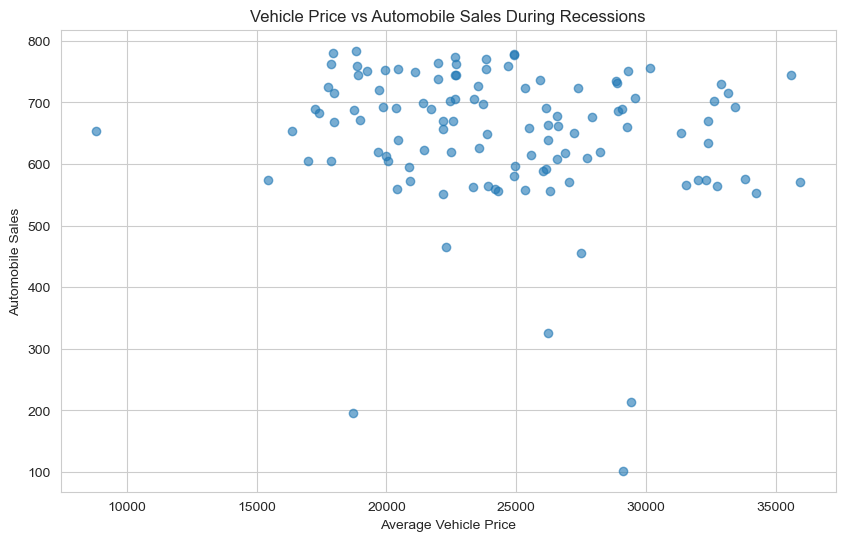

Correlation between Price and Automobile Sales:
                     Price  Automobile_Sales
Price             1.000000         -0.146819
Automobile_Sales -0.146819          1.000000


In [33]:
# Task 1.6
recession_data = df[df["Recession"] == 1]

plt.figure(figsize=(10, 6))
plt.scatter(
    recession_data["Price"],
    recession_data["Automobile_Sales"],
    alpha=0.6
)

plt.title("Vehicle Price vs Automobile Sales During Recessions")
plt.xlabel("Average Vehicle Price")
plt.ylabel("Automobile Sales")
plt.grid(True)
plt.show()

print("Correlation between Price and Automobile Sales:")
print(recession_data[["Price", "Automobile_Sales"]].corr())


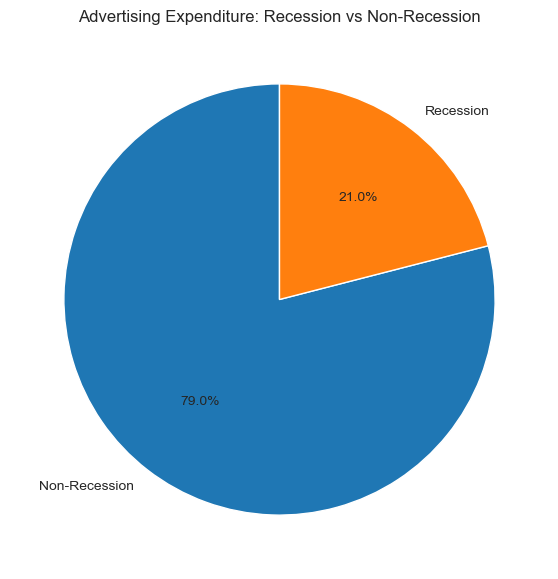

In [34]:
# Task 1.7
advertising_by_period = df.groupby("Recession")["Advertising_Expenditure"].sum()

plt.figure(figsize=(7, 7))
plt.pie(
    advertising_by_period.values,
    labels=["Non-Recession", "Recession"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Advertising Expenditure: Recession vs Non-Recession")
plt.show()


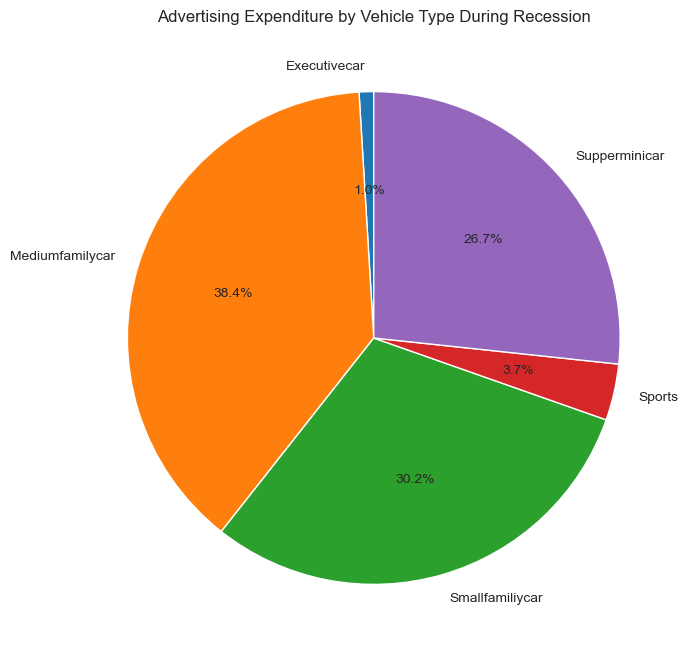

In [35]:
# Task 1.8
recession_advertising = (
    df[df["Recession"] == 1]
    .groupby("Vehicle_Type")["Advertising_Expenditure"]
    .sum()
)

plt.figure(figsize=(8, 8))
plt.pie(
    recession_advertising.values,
    labels=recession_advertising.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Advertising Expenditure by Vehicle Type During Recession")
plt.show()


<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

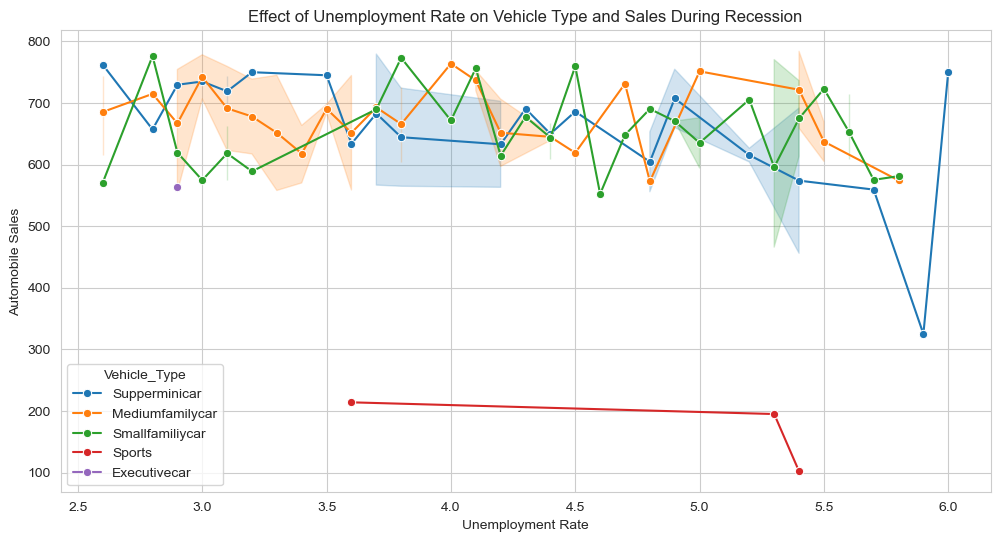

In [39]:
# Task 1.9
recession_data = df[df["Recession"] == 1]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=recession_data,
    x="unemployment_rate",
    y="Automobile_Sales",
    hue="Vehicle_Type",
    marker="o"
)

plt.title("Effect of Unemployment Rate on Vehicle Type and Sales During Recession")
plt.xlabel("Unemployment Rate")
plt.ylabel("Automobile Sales")
plt.grid(True)
plt.show()